# Part B – AutoML with PyCaret + MLflow (Steps 1–8)

**Platform:** MLflow (open-source MLOps platform, run locally) with **PyCaret** as the AutoML engine.
Every model PyCaret trains is logged to MLflow. View the runs with `mlflow ui` from this folder.

In [1]:
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.inspection import permutation_importance

from pycaret.regression import (setup, compare_models, pull, plot_model,
                                predict_model, get_config)

from data_prep import load_athletes, TARGET

SEED = 30
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

# Excluded only because they are impractically slow / memory-heavy on ~25k rows
# (kernel ridge, Theil-Sen, SVM) or are a non-model baseline (dummy).
EXCLUDE = ["kr", "tr", "svm", "dummy"]

## 1. Load the athletes dataset

In [2]:
df = load_athletes()          
print(df.shape)
df.head()

(30832, 69)


,age,height,weight,total_lift,eat_i_eat_1_3_full_cheat_meals_per_week,eat_i_eat_quality_foods_but_don_t_measure_the_amount,eat_i_eat_strict_paleo,eat_i_eat_whatever_is_convenient,eat_i_weigh_and_measure_my_food,background_i_have_no_athletic_background_besides_crossfit,...,howlong_less_than_6_months,howlong_less_than_6_months_1_2_years,howlong_less_than_6_months_2_4_years,howlong_less_than_6_months_4_years,howlong_less_than_6_months_6_12_months,howlong_less_than_6_months_6_12_months_1_2_years,howlong_less_than_6_months_6_12_months_1_2_years_2_4_years,howlong_less_than_6_months_6_12_months_1_2_years_2_4_years_4_years,howlong_less_than_6_months_6_12_months_1_2_years_2_4_years_4_years_decline_to_answer,howlong_less_than_6_months_decline_to_answer
0,30.0,71.0,200.0,1110.0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,28.0,70.0,176.0,910.0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,35.0,68.0,225.0,1335.0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,36.0,71.0,199.0,1354.0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,36.0,64.0,155.0,1225.0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 2. AutoML – find the best model (all features)

In [3]:
setup(
    data=df,
    target=TARGET,
    train_size=0.8,          # 20% hold-out test set
    fold=5,                  # 5-fold cross-validation = validation score
    normalize=True,
    session_id=SEED,
    log_experiment=True,
    experiment_name="athletes_automl_all_features",
    log_plots=False,
    verbose=True,
)
setup_summary = pull()

,Description,Value
0,Session id,30
1,Target,total_lift
2,Target type,Regression
3,Original data shape,"(30832, 69)"
4,Transformed data shape,"(30832, 69)"
5,Transformed train set shape,"(24665, 69)"
6,Transformed test set shape,"(6167, 69)"
7,Numeric features,68
8,Preprocess,True
9,Imputation type,simple


2026/11/08 19:42:26 INFO mlflow.tracking.fluent: Experiment with name 'athletes_automl_all_features' does not exist. Creating a new experiment.


In [4]:
top3_all = compare_models(n_select=3, sort="RMSE", exclude=EXCLUDE, turbo=False)
lb_all = pull()
lb_all.to_csv(RESULTS / "pycaret_leaderboard_all_features.csv")
best_all = top3_all[0]
print("Best model:", lb_all.iloc[0]["Model"])
lb_all

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
catboost,CatBoost Regressor,106.9244,19620.6968,140.0625,0.7449,0.1700,0.1623,1.4720
lightgbm,Light Gradient Boosting Machine,107.8896,19942.5109,141.2089,0.7407,0.1712,0.1637,0.3960
gbr,Gradient Boosting Regressor,109.7024,20453.3806,143.0018,0.7340,0.1728,0.1642,0.5640
xgboost,Extreme Gradient Boosting,110.4518,20886.5840,144.5140,0.7284,0.1738,0.1652,0.1240
rf,Random Forest Regressor,112.0549,21378.5577,146.2053,0.7220,0.1753,0.1657,2.3280
mlp,MLP Regressor,112.0487,21502.4199,146.6115,0.7204,0.1762,0.1676,5.9860
ard,Automatic Relevance Determination,113.4321,21978.6352,148.2247,0.7142,0.1780,0.1681,1.5220
br,Bayesian Ridge,113.4470,21988.6359,148.2579,0.7141,0.1780,0.1681,0.0400
ridge,Ridge Regression,113.4413,21988.9137,148.2589,0.7141,0.1781,0.1681,0.3260
lasso,Lasso Regression,113.5926,22006.7434,148.3196,0.7138,0.1779,0.1681,0.3380


Best model: CatBoost Regressor


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
catboost,CatBoost Regressor,106.9244,1.962070e+04,140.0625,7.449000e-01,0.1700,0.1623,1.472
lightgbm,Light Gradient Boosting Machine,107.8896,1.994251e+04,141.2089,7.407000e-01,0.1712,0.1637,0.396
gbr,Gradient Boosting Regressor,109.7024,2.045338e+04,143.0018,7.340000e-01,0.1728,0.1642,0.564
xgboost,Extreme Gradient Boosting,110.4518,2.088658e+04,144.5140,7.284000e-01,0.1738,0.1652,0.124
rf,Random Forest Regressor,112.0549,2.137856e+04,146.2053,7.220000e-01,0.1753,0.1657,2.328
mlp,MLP Regressor,112.0487,2.150242e+04,146.6115,7.204000e-01,0.1762,0.1676,5.986
ard,Automatic Relevance Determination,113.4321,2.197864e+04,148.2247,7.142000e-01,0.1780,0.1681,1.522
br,Bayesian Ridge,113.4470,2.198864e+04,148.2579,7.141000e-01,0.1780,0.1681,0.040
ridge,Ridge Regression,113.4413,2.198891e+04,148.2589,7.141000e-01,0.1781,0.1681,0.326
lasso,Lasso Regression,113.5926,2.200674e+04,148.3196,7.138000e-01,0.1779,0.1681,0.338


In [5]:
# Hold-out test performance of the best model
predict_model(best_all)
holdout_all = pull()
holdout_all

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,CatBoost Regressor,109.1406,20744.0428,144.0279,0.7390,0.1998,0.2368


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,CatBoost Regressor,109.1406,20744.0428,144.0279,0.739,0.1998,0.2368


## 3. Data insights from the AutoML run

In [6]:
def save_plot(model, plot, name):
    """Render a PyCaret plot, move it into results/, and display it."""
    fname = plot_model(model, plot=plot, save=True)
    dest = RESULTS / f"{name}.png"
    shutil.move(fname, dest)
    display(Image(str(dest)))

setup_summary   # dataset shape, feature types, missing values, transformations applied

,Description,Value
0,Session id,30
1,Target,total_lift
2,Target type,Regression
3,Original data shape,"(30832, 69)"
4,Transformed data shape,"(30832, 69)"
5,Transformed train set shape,"(24665, 69)"
6,Transformed test set shape,"(6167, 69)"
7,Numeric features,68
8,Preprocess,True
9,Imputation type,simple


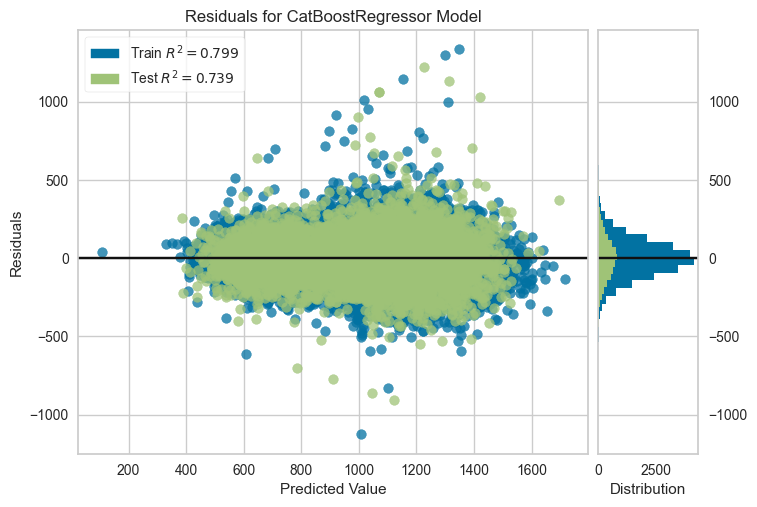

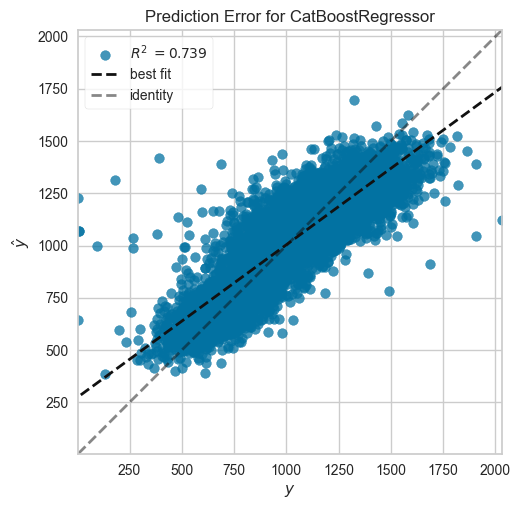

In [7]:
save_plot(best_all, "residuals", "pycaret_best_residuals")
save_plot(best_all, "error", "pycaret_best_prediction_error")

## 4. Top 5 features

In [8]:
def top_features(model, n=5):
    """Importance as reported by the model (tree importances or |coefficients|);
    falls back to permutation importance for models that report neither."""
    X = get_config("X_train_transformed")
    if hasattr(model, "feature_importances_"):
        imp = model.feature_importances_
    elif hasattr(model, "coef_"):
        imp = np.abs(np.ravel(model.coef_))
    else:
        imp = permutation_importance(
            model, get_config("X_test_transformed"), get_config("y_test_transformed"),
            n_repeats=5, random_state=SEED, scoring="neg_root_mean_squared_error",
        ).importances_mean
    return pd.Series(imp, index=X.columns).sort_values(ascending=False).head(n)

top5 = top_features(best_all)
top5.to_csv(RESULTS / "pycaret_top5_features.csv")
top5

gender_male                                                            34.795184
weight                                                                 19.609860
age                                                                     8.051717
height                                                                  4.349234
experience_i_have_completed_the_crossfit_level_1_certificate_course     3.432249
dtype: float64

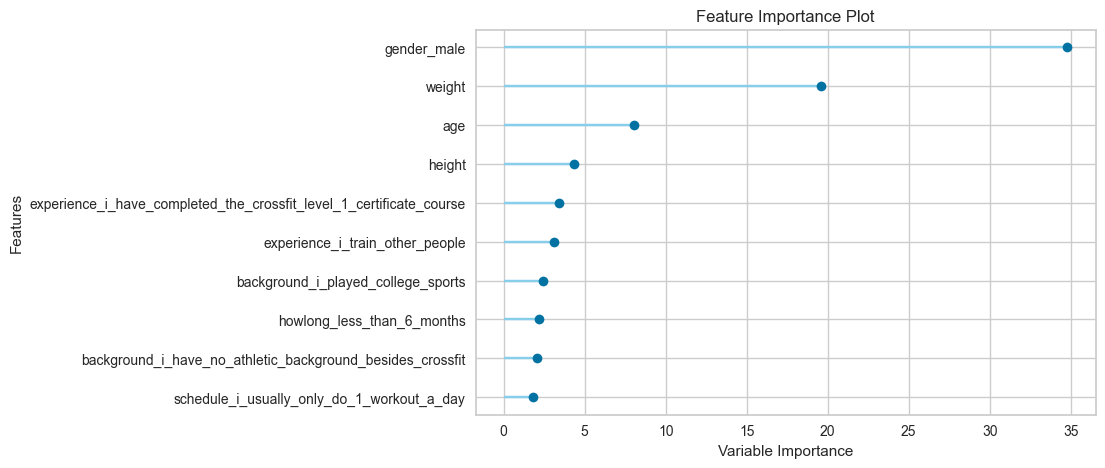

In [9]:
try:
    save_plot(best_all, "feature", "pycaret_best_feature_importance")
except Exception as e:
    print("Feature-importance plot not available for this model type:", e)

## 5. Top 3 models by validation score (5-fold CV RMSE)

### 5.1 All features

In [10]:
cols = ["Model", "MAE", "RMSE", "R2", "TT (Sec)"]
top3_val_all = lb_all.sort_values("RMSE").head(3)[cols]
top3_val_all

,Model,MAE,RMSE,R2,TT (Sec)
catboost,CatBoost Regressor,106.9244,140.0625,0.7449,1.472
lightgbm,Light Gradient Boosting Machine,107.8896,141.2089,0.7407,0.396
gbr,Gradient Boosting Regressor,109.7024,143.0018,0.7340,0.564


### 5.2 Only the top 3 features

In [11]:
top3_feats = list(top5.index[:3])
print("Top 3 features:", top3_feats)

setup(
    data=df[top3_feats + [TARGET]],
    target=TARGET,
    train_size=0.8,
    fold=5,
    normalize=True,
    session_id=SEED,
    log_experiment=True,
    experiment_name="athletes_automl_top3_features",
    log_plots=False,
    verbose=False,
)
top3_top = compare_models(n_select=3, sort="RMSE", exclude=EXCLUDE, turbo=False)
lb_top = pull()
lb_top.to_csv(RESULTS / "pycaret_leaderboard_top3_features.csv")

predict_model(top3_top[0])
holdout_top = pull()

top3_val_top = lb_top.sort_values("RMSE").head(3)[cols]
top3_val_top

Top 3 features: ['gender_male', 'weight', 'age']


2026/11/08 19:44:56 INFO mlflow.tracking.fluent: Experiment with name 'athletes_automl_top3_features' does not exist. Creating a new experiment.


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
gbr,Gradient Boosting Regressor,132.5101,28958.5527,170.1490,0.6235,0.1978,0.1870,0.1500
mlp,MLP Regressor,132.9390,29096.8926,170.5545,0.6217,0.1982,0.1875,2.2460
lightgbm,Light Gradient Boosting Machine,132.9048,29180.4457,170.7993,0.6206,0.1983,0.1877,0.2440
catboost,CatBoost Regressor,132.9502,29202.8378,170.8697,0.6203,0.1984,0.1878,0.6640
xgboost,Extreme Gradient Boosting,135.1644,30240.3879,173.8817,0.6068,0.2012,0.1903,0.0440
lr,Linear Regression,137.5389,31101.7996,176.3245,0.5956,0.2038,0.1925,0.0420
ridge,Ridge Regression,137.5390,31101.7910,176.3245,0.5956,0.2038,0.1925,0.0100
lar,Least Angle Regression,137.5391,31101.7934,176.3245,0.5956,0.2038,0.1925,0.0120
ard,Automatic Relevance Determination,137.5394,31101.7945,176.3245,0.5956,0.2038,0.1925,0.0160
br,Bayesian Ridge,137.5387,31101.7816,176.3245,0.5956,0.2038,0.1925,0.0100


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Gradient Boosting Regressor,135.6465,30978.1955,176.0062,0.6102,0.2270,0.2690


,Model,MAE,RMSE,R2,TT (Sec)
gbr,Gradient Boosting Regressor,132.5101,170.1490,0.6235,0.150
mlp,MLP Regressor,132.9390,170.5545,0.6217,2.246
lightgbm,Light Gradient Boosting Machine,132.9048,170.7993,0.6206,0.244


## 6. Top 3 models by speed (training time, `TT (Sec)`)

### 6.1 All features

In [12]:
top3_speed_all = lb_all.sort_values("TT (Sec)").head(3)[cols]
top3_speed_all

,Model,MAE,RMSE,R2,TT (Sec)
llar,Lasso Least Angle Regression,113.5924,148.3197,0.7138,0.028
lar,Least Angle Regression,115.5911,151.9841,0.6993,0.030
omp,Orthogonal Matching Pursuit,125.1923,161.7293,0.6597,0.038


### 6.2 Only the top 3 features

In [13]:
top3_speed_top = lb_top.sort_values("TT (Sec)").head(3)[cols]
top3_speed_top

,Model,MAE,RMSE,R2,TT (Sec)
en,Elastic Net,145.7800,184.8352,0.5557,0.008
llar,Lasso Least Angle Regression,137.5530,176.3312,0.5956,0.010
br,Bayesian Ridge,137.5387,176.3245,0.5956,0.010


## 7. Comparison with the Part A model

In [14]:
# Part A results (Keras MLP on the Databricks feature store, test set)
part_a = pd.DataFrame([
    {"Source": "Part A – best (v1_hp_b, MLP)",    "RMSE": 145.6, "R2": 0.725, "Train time (s)": 19.0},
    {"Source": "Part A – fastest (v1_hp_a, MLP)", "RMSE": 146.2, "R2": 0.722, "Train time (s)": 4.6},
])

automl = pd.DataFrame([
    {"Source": f"PyCaret – best, all features ({lb_all.iloc[0]['Model']})",
     "CV RMSE": lb_all.iloc[0]["RMSE"], "RMSE": holdout_all["RMSE"].iloc[0],
     "R2": holdout_all["R2"].iloc[0], "Train time (s)": lb_all.iloc[0]["TT (Sec)"]},
    {"Source": f"PyCaret – best, top 3 features ({lb_top.iloc[0]['Model']})",
     "CV RMSE": lb_top.iloc[0]["RMSE"], "RMSE": holdout_top["RMSE"].iloc[0],
     "R2": holdout_top["R2"].iloc[0], "Train time (s)": lb_top.iloc[0]["TT (Sec)"]},
])

comparison = pd.concat([automl, part_a], ignore_index=True)
comparison.to_csv(RESULTS / "comparison_vs_part_a.csv", index=False)
comparison

,Source,CV RMSE,RMSE,R2,Train time (s)
0,"PyCaret – best, all features (CatBoost Regressor)",140.0625,144.0279,0.7390,1.472
1,"PyCaret – best, top 3 features (Gradient Boost...",170.1490,176.0062,0.6102,0.150
2,"Part A – best (v1_hp_b, MLP)",NaN,145.6000,0.7250,19.000
3,"Part A – fastest (v1_hp_a, MLP)",NaN,146.2000,0.7220,4.600


## 8. Is the AutoML no-code, low-code, or full-code?

**Low-code.** PyCaret is driven from Python, but the whole AutoML workflow (preprocessing, cross-validation, training and tuning ~20 algorithms, ranking them, and logging every run to MLflow) is handled by two function calls: `setup()` and `compare_models()`. There is no graphical, drag-and-drop interface (so it is not no-code), but it replaces hundreds of lines of hand-written training and evaluation code (so it is not full-code).